# 05 · Metrics and figures for all detectors

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SheridanLu/detecting-the-detector/blob/main/notebooks/05_metrics_and_figures.ipynb)

> **REPLAY NOTEBOOK - no model is trained or run here.**
> Every number below is recomputed from *saved scores* in `data/`: the scores our three detector families gave each
> essay in the original run on an 8x A40 GPU server (logistic regression, RoBERTa, Qwen3.8-27B + LoRA), the scores of
> two open-source detectors (Binoculars and Fast-DetectGPT, both using the falcon-7b model pair), and the scores of
> seven commercial detectors archived by Liang et al. (2023). Re-running the models: notebook 02 (logistic
> regression, CPU), 03 (RoBERTa, GPU); Qwen 27B and the falcon-7b pair cannot run on free Colab.

**Goal.** Recompute the headline tables from the saved scores with one shared piece of code for all detectors, check
them against the tables archived by the original run, and draw the main figures.

| Mode | What runs | Expected time | GPU |
|---|---|---|---|
| SMOKE | everything, with 20 bootstrap resamples for the confidence intervals | < 30 s | no |
| FAST (default) | everything, 200 bootstrap resamples | < 30 s | no |
| FULL | everything, 1,000 bootstrap resamples (as in the original run) | < 1 min | no |

In [1]:
# --- Setup: find the repository (or download it on Colab) and install anything Colab does not have ---
import os, sys, time, pathlib, subprocess
T0 = time.time()
REPO_URL = "https://github.com/SheridanLu/detecting-the-detector"

def _is_repo(p):
    return (p / "ddlib" / "__init__.py").is_file() and (p / "data").is_dir()

def _locate_or_fetch():
    here = pathlib.Path.cwd().resolve()
    for p in [pathlib.Path(os.environ.get("DD_REPO", here)), here, *here.parents]:
        if _is_repo(p):
            return p                                   # mode 1: already inside the repo
    dest = pathlib.Path("/content" if os.path.isdir("/content") else here) / "detecting-the-detector"
    if not _is_repo(dest) and not dest.exists():       # mode 2: git clone (token optional, for a private repo)
        tok = os.environ.get("GH_TOKEN")
        try:
            from google.colab import userdata
            tok = userdata.get("GH_TOKEN") or tok
        except Exception:
            pass
        url = REPO_URL.replace("https://", f"https://x-access-token:{tok}@") if tok else REPO_URL
        subprocess.run(["git", "clone", "--depth", "1", "-q", url, str(dest)], env=dict(os.environ, GIT_TERMINAL_PROMPT="0"))
        if tok and dest.exists():
            subprocess.run(["git", "-C", str(dest), "remote", "set-url", "origin", REPO_URL])   # token not kept on disk
    if _is_repo(dest):
        return dest
    return None                                        # mode 3 (zip upload) is handled by ddlib below

root = _locate_or_fetch()
if root is None:
    # Zip fallback: needs the small ddlib/paths.py helper, which we cannot import yet, so do it here.
    print("Could not find or clone the repository.\n"
          "Fix 1: add a Colab secret GH_TOKEN (key icon, left sidebar) with read access, allow notebook access, re-run.\n"
          f"Fix 2: download the repo as a zip ({REPO_URL} > Code > Download ZIP) and upload it when asked.")
    from google.colab import files
    import zipfile
    up = files.upload()
    zipfile.ZipFile(next(k for k in up if k.endswith(".zip"))).extractall("/content")
    root = next(p.parent.parent for p in pathlib.Path("/content").glob("*/ddlib/__init__.py") if _is_repo(p.parent.parent))
sys.path.insert(0, str(root))
os.chdir(root)                                         # all paths below are relative to the repo root

_req = [l.strip() for l in open("requirements-colab.txt") if l.strip() and not l.startswith("#")]
if _req:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_req], check=True)

from ddlib import get_repo
REPO = get_repo()
print("Python", sys.version.split()[0])

Repository found. Data folder present: True
Python 3.12.16


## Configuration

In [2]:
# --- CONFIG ---------------------------------------------------------------------------------------
# MODE = "SMOKE" (seconds; tiny version used for automated testing), "FAST" (default) or "FULL" (paper setting).
# Change the string below to switch. (The DD_MODE environment variable is only used by automated tests.)
MODE = os.environ.get("DD_MODE", "FAST").upper()
assert MODE in ("SMOKE", "FAST", "FULL"), MODE
N_BOOT = {"SMOKE": 20, "FAST": 200, "FULL": 1000}[MODE]      # resamples for confidence intervals of AUCs
N_BOOT_PAIRED = 50 if MODE == "SMOKE" else 1000                # paired test: 1,000 as in the original (needed to match its intervals)
FIG_DIR = pathlib.Path("outputs/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
print("MODE =", MODE, "| bootstrap resamples:", N_BOOT)

MODE = FAST | bootstrap resamples: 200


## 1. Load every saved score
One row per (detector, essay). For our own detectors there is one file per training arm and seed.

In [3]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from ddlib import data as D, metrics as M, plots as P
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)

train_ids = D.train_exam_ids()
own = {}                                   # (model, arm, seed) -> scores, 4,000 + 4,000 training essays
for model in ["LR", "RoBERTa", "Qwen27B"]:
    for arm in "ABCD":
        for s in D.SEEDS[model]:
            own[(model, arm, s)] = D.load_preds(model, arm, s)
osd = {name: D.load_opensource(name) for name in ["Binoculars", "FastDetectGPT"]}
com = D.load_commercial()
inv = pd.DataFrame([dict(detector=m, arms="".join(sorted({a for (mm, a, s) in own if mm == m})),
                         seeds=len(D.SEEDS[m]), files=sum(1 for k in own if k[0] == m), scored_essays_per_file=len(own[(m, "A", 0)]))
                    for m in ["LR", "RoBERTa", "Qwen27B"]] +
                   [dict(detector=k, arms="-", seeds=1, files=1, scored_essays_per_file=len(v)) for k, v in osd.items()] +
                   [dict(detector="7 commercial (Liang et al. 2023)", arms="-", seeds=1, files=1,
                         scored_essays_per_file=f"{com.essay_id.nunique()} (Liang set only)")])
display(inv)

,detector,arms,seeds,files,scored_essays_per_file
0,LR,ABCD,5,20,14272
1,RoBERTa,ABCD,5,20,14272
2,Qwen27B,ABCD,2,8,14272
3,Binoculars,-,1,1,14272
4,FastDetectGPT,-,1,1,14272
5,7 commercial (Liang et al. 2023),-,1,1,925 (Liang set only)


## 2. Table 1: who gets flagged? (threshold 0.5)
Rows: detector and training arm (mean over seeds). Columns starting with **FP** are *false-flag rates*: the share of
human essays called AI (lower is better). Columns starting with **TPR** are *detection rates*: the share of AI essays
caught (higher is better). FCE / W&I essays that arm C trained on are excluded everywhere.
* FP_TOEFL: non-native TOEFL essays · FP_Hewlett: US 8th-grade essays (familiar to the detectors)
* FP_nativeOOD_mean: mean of three unfamiliar native sets (college essays, CS224N, LOCNESS)
* bias_TOEFLvsHewlett: bias AUC (0.5 = no bias)

In [4]:
rows = []
for (model, arm, s), p in own.items():
    rows.append(dict(model=model, arm=arm, seed=s, **M.run_row(p, train_ids)))
for name, p in osd.items():
    rows.append(dict(model=name, arm="-", seed=0, **M.run_row(p, train_ids)))
runs = pd.DataFrame(rows)
cols = list(M.FP_COLS) + list(M.TPR_COLS) + ["AUC_ArguGPTvsTOEFL", "AUC_Liang352vsHewlett", "bias_TOEFLvsHewlett", "bias_TOEFLvsNativeOOD", "FP_nativeOOD_mean"]
CM = runs.groupby(["model", "arm"], sort=False)[cols].mean()
CM["TOEFL_sd"] = runs.groupby(["model", "arm"], sort=False).FP_TOEFL.std()
CM["n_seeds"] = runs.groupby(["model", "arm"], sort=False).size()
display(CM[["FP_TOEFL", "FP_Hewlett", "FP_nativeOOD_mean", "TPR_Liang352", "TPR_ArguGPT", "bias_TOEFLvsHewlett", "n_seeds"]].round(3))

old = D.load_result("model_comparison_all")
chk1 = M.compare_frames(CM.reset_index(), old, cols + ["TOEFL_sd"], ["model", "arm"], tol=1e-9)
print(f"Check against data/results/model_comparison_all.csv: {(chk1.result == 'PASS').sum()} of {len(chk1)} columns identical "
      f"(largest difference {chk1.max_abs_diff.max():.1e}) ->", "PASS" if (chk1.result == "PASS").all() else "FAIL")

FP_TOEFL  FP_Hewlett  FP_nativeOOD_mean  TPR_Liang352  TPR_ArguGPT  bias_TOEFLvsHewlett  n_seeds
model         arm                                                                                                  
LR            A       0.798       0.020              0.851         0.995        0.924                0.987        5
              B       0.422       0.011              0.786         0.978        0.785                0.972        5
              C       0.079       0.000              0.428         0.947        0.615                0.880        5
              D       0.468       0.002              0.222         0.891        0.727                0.961        5
RoBERTa       A       0.987       0.016              0.687         1.000        0.994                0.999        5
              B       0.941       0.002              0.702         1.000        0.993                0.999        5
              C       0.262       0.005              0.453         0.997        0.957                0.698        5
              D       0.905       0.020              0.291         0.973        0.992                0.992        5
Qwen27B       A       0.396       0.062              0.293         1.000        0.996                0.920        2
              B       0.297       0.040              0.287         1.000        0.995                0.945        2
              C       0.049       0.040              0.091         1.000        0.994                0.637        2
              D       0.346       0.057              0.068         0.994        0.995                0.939        2
Binoculars    -       0.066       0.000              0.000         0.710        0.973                0.868        1
FastDetectGPT -       0.352       0.034              0.110         0.892        0.993                0.819        1

Check against data/results/model_comparison_all.csv: 21 of 21 columns identical (largest difference 2.2e-16) -> PASS


## 3. Table 2: the pre-registered primary endpoints
Written down before the GPU runs (`a40/PREREG*.md`):
1. TOEFL false-flag rate at the *90%-detection threshold* (each run picks the threshold that catches 90% of the
   validation AI essays);
2. bias AUC, TOEFL vs Hewlett;
3. detection must not get worse: AUC of AI essays written on the TOEFL prompts (ArguGPT) vs the TOEFL essays.

For Qwen 27B the 90%-detection threshold is degenerate (its scores are nearly all 0 or 1, so the threshold lands near
1.0 and almost nothing is flagged): use its bias AUC and the 0.5-threshold rates instead.

In [5]:
prim = runs[runs.model.isin(["LR", "RoBERTa", "Qwen27B"])].copy()
P1 = prim.groupby(["model", "arm"], sort=False)[["flag90_TOEFL", "bias_TOEFLvsHewlett", "AUC_ArguGPTvsTOEFL"]].agg(["mean", "std"]).round(3)
display(P1)

# check every run against the archived follow-up tables (one per model family)
src = {"LR": "followup_runs", "RoBERTa": "followup_runs_roberta", "Qwen27B": "followup_runs_qwen"}
chk2 = []
for model, f in src.items():
    o = D.load_result(f).rename(columns={"P1_toefl_flag90": "flag90_TOEFL", "bias_auc_vs_hewlett": "bias_TOEFLvsHewlett",
                                         "P3_arguGPT_vs_toefl": "AUC_ArguGPTvsTOEFL", "native_ood_mean90": "flag90_nativeOOD_mean"})
    n = prim[prim.model == model]
    c = M.compare_frames(n, o, ["flag90_TOEFL", "bias_TOEFLvsHewlett", "AUC_ArguGPTvsTOEFL", "flag90_nativeOOD_mean"], ["arm", "seed"], tol=1e-9)
    chk2.append(c.assign(model=model))
chk2 = pd.concat(chk2); display(chk2)
print("Check against data/results/followup_runs*.csv:", "PASS" if (chk2.result == "PASS").all() else "FAIL")

flag90_TOEFL        bias_TOEFLvsHewlett        AUC_ArguGPTvsTOEFL       
                    mean    std                mean    std               mean    std
model   arm                                                                         
LR      A          0.807  0.029               0.987  0.003              0.739  0.015
        B          0.418  0.034               0.972  0.004              0.773  0.012
        C          0.079  0.009               0.880  0.018              0.880  0.006
        D          0.486  0.036               0.961  0.011              0.702  0.014
RoBERTa A          0.662  0.132               0.999  0.001              0.908  0.042
        B          0.633  0.096               0.999  0.001              0.914  0.022
        C          0.097  0.024               0.698  0.082              0.960  0.009
        D          0.578  0.023               0.992  0.005              0.921  0.023
Qwen27B A          0.011  0.000               0.920  0.040              0.990  0.000
        B          0.011  0.000               0.945  0.005              0.989  0.000
        C          0.011  0.000               0.637  0.001              0.989  0.002
        D          0.022  0.016               0.939  0.045              0.987  0.005

,column,rows_compared,max_abs_diff,result,model
0,flag90_TOEFL,20,0.0,PASS,LR
1,bias_TOEFLvsHewlett,20,0.0,PASS,LR
2,AUC_ArguGPTvsTOEFL,20,0.0,PASS,LR
3,flag90_nativeOOD_mean,20,0.0,PASS,LR
0,flag90_TOEFL,20,0.0,PASS,RoBERTa
1,bias_TOEFLvsHewlett,20,0.0,PASS,RoBERTa
2,AUC_ArguGPTvsTOEFL,20,0.0,PASS,RoBERTa
3,flag90_nativeOOD_mean,20,0.0,PASS,RoBERTa
0,flag90_TOEFL,8,0.0,PASS,Qwen27B
1,bias_TOEFLvsHewlett,8,0.0,PASS,Qwen27B


Check against data/results/followup_runs*.csv: PASS


In [6]:
# bias AUC with a 95% bootstrap interval for the detectors that were not trained by us
rng = np.random.default_rng(0)
ext = []
for det in M.COMMERCIAL:
    by = M.by_corpus(com[com.detector == det])
    a, lo, hi = M.auc_ci(by[M.TOEFL], by[M.HEWLETT], n_boot=N_BOOT, rng=rng)
    ext.append(dict(detector=det, kind="commercial (2023)", TOEFL_flagged=M.flag_rate(by[M.TOEFL]), Hewlett_flagged=M.flag_rate(by[M.HEWLETT]),
                    bias_AUC=a, ci_low=lo, ci_high=hi,
                    detection_AUC_AI352=M.auc(np.concatenate([by[c].to_numpy() for c in M.AI352]), np.r_[by[M.TOEFL].to_numpy(), by[M.HEWLETT].to_numpy()])))
for name, p in osd.items():
    by = M.by_corpus(p)
    a, lo, hi = M.auc_ci(by[M.TOEFL], by[M.HEWLETT], n_boot=N_BOOT, rng=rng)
    ext.append(dict(detector=name, kind="open-source (2024)", TOEFL_flagged=M.flag_rate(by[M.TOEFL]), Hewlett_flagged=M.flag_rate(by[M.HEWLETT]),
                    bias_AUC=a, ci_low=lo, ci_high=hi,
                    detection_AUC_AI352=M.auc(np.concatenate([by[c].to_numpy() for c in M.AI352]), np.r_[by[M.TOEFL].to_numpy(), by[M.HEWLETT].to_numpy()])))
ext = pd.DataFrame(ext); display(ext.round(3))

mr = D.load_result("metrics_runs")
mr = mr[mr.model.isin(["commercial", "Binoculars", "FastDetectGPT"])].assign(detector=lambda d: d.detector.astype(str))
mr = mr.rename(columns={"rate_t05_TOEFL_real_91": "TOEFL_flagged", "rate_t05_HewlettStudentEssay_real_88": "Hewlett_flagged",
                        "bias_TOEFL_vs_Hewlett": "bias_AUC", "det_AI352_vs_LiangHuman2": "detection_AUC_AI352"})
chk3 = M.compare_frames(ext, mr, ["TOEFL_flagged", "Hewlett_flagged", "bias_AUC", "detection_AUC_AI352"], ["detector"], tol=1e-9)
display(chk3)
print("Check against data/results/metrics_runs.csv (point estimates; intervals are fresh resamples):",
      "PASS" if (chk3.result == "PASS").all() and chk3.rows_compared.min() == 9 else "FAIL")

,detector,kind,TOEFL_flagged,Hewlett_flagged,bias_AUC,ci_low,ci_high,detection_AUC_AI352
0,Crossplag,commercial (2023),0.516,0.125,0.880,0.832,0.928,0.439
1,GPTZero,commercial (2023),0.516,0.000,0.985,0.970,0.997,0.603
2,HFOpenAI,commercial (2023),0.582,0.091,0.902,0.858,0.947,0.456
3,OriginalityAI,commercial (2023),0.758,0.011,0.963,0.933,0.985,0.538
4,Quil,commercial (2023),0.747,0.091,0.931,0.887,0.963,0.497
5,Sapling,commercial (2023),0.681,0.045,0.836,0.774,0.889,0.462
6,ZeroGPT,commercial (2023),0.527,0.011,0.895,0.854,0.938,0.467
7,Binoculars,open-source (2024),0.066,0.000,0.868,0.817,0.913,0.931
8,FastDetectGPT,open-source (2024),0.352,0.034,0.819,0.760,0.876,0.944


,column,rows_compared,max_abs_diff,result
0,TOEFL_flagged,9,0.0,PASS
1,Hewlett_flagged,9,0.0,PASS
2,bias_AUC,9,0.0,PASS
3,detection_AUC_AI352,9,0.0,PASS


Check against data/results/metrics_runs.csv (point estimates; intervals are fresh resamples): PASS


## 4. Table 3: precision, recall and F1 on the Liang test set
394 human essays + 352 GPT-3 essays; AI is the positive class; threshold 0.5 for every detector.
*F1 on TOEFL / Hewlett* uses a balanced precision (as if that human group and the AI essays were equally common), so
the two human groups can be compared. Two commercial detectors (Quil, Sapling) have no scores for the 145 CS224N human
essays, so they are evaluated on 249 human essays.

In [7]:
prf_rows = []
for (model, arm, s), p in own.items():
    prf_rows.append(dict(model=model, arm=arm, run=D.run_name(arm, s), **M.liang_prf_from_scores(p)))
for name, p in osd.items():
    prf_rows.append(dict(model=name, arm="-", run=name, **M.liang_prf_from_scores(p)))
for det in M.COMMERCIAL:
    prf_rows.append(dict(model="commercial", arm="-", run=det, **M.liang_prf_from_scores(com[com.detector == det])))
PRF = pd.DataFrame(prf_rows)
keys = ["accuracy", "precision", "recall", "f1", "f1_bal_TOEFL", "f1_bal_Hewlett"]
PRF_sum = PRF.groupby(["model", "arm", PRF.run.where(PRF.model == "commercial", "")], sort=False)[keys].mean()
PRF_sum.index.names = ["model", "arm", "detector"]
display(PRF_sum.round(3))

old = D.load_result("prf1_runs")
chk4 = M.compare_frames(PRF, old, keys + ["n_human", "n_ai"], ["model", "run"], tol=1e-9)
print(f"Check against data/results/prf1_runs.csv ({chk4.rows_compared.iloc[0]} runs):", "PASS" if (chk4.result == "PASS").all() else "FAIL")

accuracy  precision  recall     f1  f1_bal_TOEFL  f1_bal_Hewlett
model         arm detector                                                                       
LR            A                     0.628      0.560   0.995  0.716         0.713           0.987
              B                     0.682      0.600   0.978  0.744         0.815           0.983
              C                     0.773      0.689   0.947  0.798         0.935           0.973
              D                     0.781      0.715   0.891  0.793         0.755           0.940
RoBERTa       A                     0.602      0.542   1.000  0.703         0.670           0.992
              B                     0.609      0.547   1.000  0.707         0.680           0.999
              C                     0.769      0.673   0.997  0.803         0.883           0.996
              D                     0.769      0.680   0.973  0.800         0.676           0.976
Qwen27B       A                     0.806      0.710   1.000  0.830         0.839           0.970
              B                     0.817      0.727   1.000  0.840         0.871           0.981
              C                     0.942      0.894   1.000  0.943         0.976           0.981
              D                     0.916      0.852   0.994  0.917         0.850           0.970
Binoculars    -                     0.855      0.977   0.710  0.822         0.800           0.831
FastDetectGPT -                     0.879      0.858   0.892  0.875         0.795           0.926
commercial    -   Crossplag         0.556      0.571   0.239  0.337         0.272           0.350
                  GPTZero           0.538      0.533   0.159  0.245         0.190           0.275
                  HFOpenAI          0.567      0.594   0.261  0.363         0.284           0.387
                  OriginalityAI     0.601      0.622   0.392  0.481         0.365           0.559
                  Quil              0.512      0.638   0.386  0.481         0.362           0.523
                  Sapling           0.547      0.687   0.418  0.519         0.398           0.571
                  ZeroGPT           0.572      0.622   0.239  0.345         0.270           0.382

Check against data/results/prf1_runs.csv (57 runs): PASS


## 5. Paired test: does the training set change which TOEFL essays get flagged?
Same seed, same 91 TOEFL essays, two arms. *diff* = flag rate of arm X minus arm Y at the 90%-detection threshold;
*p* = exact McNemar test. Same code and random-number order as `a40/followup_metrics*.py`, so with 1,000 resamples
the intervals should equal the archived ones exactly.

In [8]:
pairs = []
for model, f in (("LR", "followup_paired"), ("RoBERTa", "followup_paired_roberta"), ("Qwen27B", "followup_paired_qwen")):
    rng = np.random.default_rng(0)                         # each original script started its own generator
    flags = {}
    for arm in "ABCD":
        for s in D.SEEDS[model]:
            p = M.drop_train_exams(own[(model, arm, s)], train_ids)
            flags[(arm, s)] = (p[p.corpus == M.TOEFL].set_index("essay_id").score >= M.thr_tpr90(p)).astype(int)
    for x, y in (("C", "A"), ("C", "D"), ("B", "A")):
        for s in D.SEEDS[model]:
            pairs.append(dict(model=model, pair=f"{x}-{y}", seed=s, **M.paired_flags(flags[(x, s)], flags[(y, s)], n_boot=N_BOOT_PAIRED, rng=rng)))
PAIR = pd.DataFrame(pairs)
summary = PAIR.groupby(["model", "pair"], sort=False).agg(mean_diff=("diff", "mean"), seeds_p_below_0_05=("p", lambda v: f"{(v < 0.05).sum()}/{len(v)}"))
display(summary.round(3))

old = pd.concat([D.load_result(f).assign(model=m) for m, f in (("LR", "followup_paired"), ("RoBERTa", "followup_paired_roberta"), ("Qwen27B", "followup_paired_qwen"))])
cols5 = ["rate_x", "rate_y", "diff", "p"] + (["lo", "hi"] if N_BOOT_PAIRED == 1000 else [])
chk5 = M.compare_frames(PAIR, old, cols5, ["model", "pair", "seed"], tol=1e-9)
display(chk5)
print("Check against data/results/followup_paired*.csv:", "PASS" if (chk5.result == "PASS").all() else "FAIL",
      "" if N_BOOT_PAIRED == 1000 else "(intervals not compared in SMOKE mode)")

mean_diff seeds_p_below_0_05
model   pair                              
LR      C-A      -0.727                5/5
        C-D      -0.407                5/5
        B-A      -0.389                5/5
RoBERTa C-A      -0.565                5/5
        C-D      -0.481                5/5
        B-A      -0.029                2/5
Qwen27B C-A       0.000                0/2
        C-D      -0.011                0/2
        B-A       0.000                0/2

,column,rows_compared,max_abs_diff,result
0,rate_x,36,0.0,PASS
1,rate_y,36,0.0,PASS
2,diff,36,0.0,PASS
3,p,36,0.0,PASS
4,lo,36,0.0,PASS
5,hi,36,0.0,PASS


Check against data/results/followup_paired*.csv: PASS 


## 6. Figure 1: false flags by training set, for the three models
Grey: native essays like the training data. Purple: native essays of an unfamiliar kind. Red: TOEFL (non-native).
Look at the red bars: they fall from A to C for every model, while D (more native essays, the control) helps much
less. The purple bars show that the detectors also misjudge native writing they have not seen before.

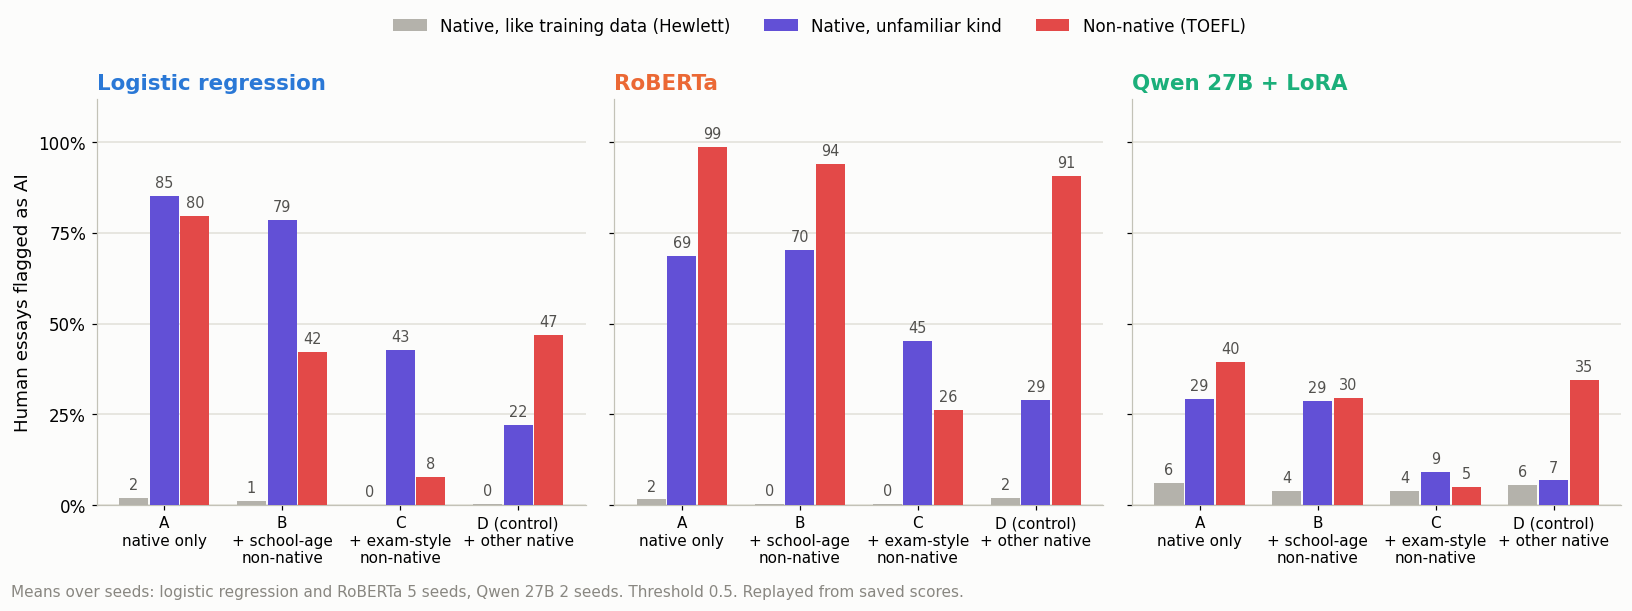

In [9]:
fig = P.flags_by_arm(CM, seeds_note="Means over seeds: logistic regression and RoBERTa 5 seeds, Qwen 27B 2 seeds. Threshold 0.5. Replayed from saved scores.")
fig.savefig(FIG_DIR / "fig1_false_flags_by_arm.png", bbox_inches="tight"); plt.show()

## 7. Figure 2: the trend A -> B -> C, with control D
TOEFL false-flag rate for each model as the human side of the training data changes. Error bars: SD across seeds.
The grey band is the range of the seven commercial detectors (2023); the purple lines are the two open-source
detectors, which were not trained on our data.

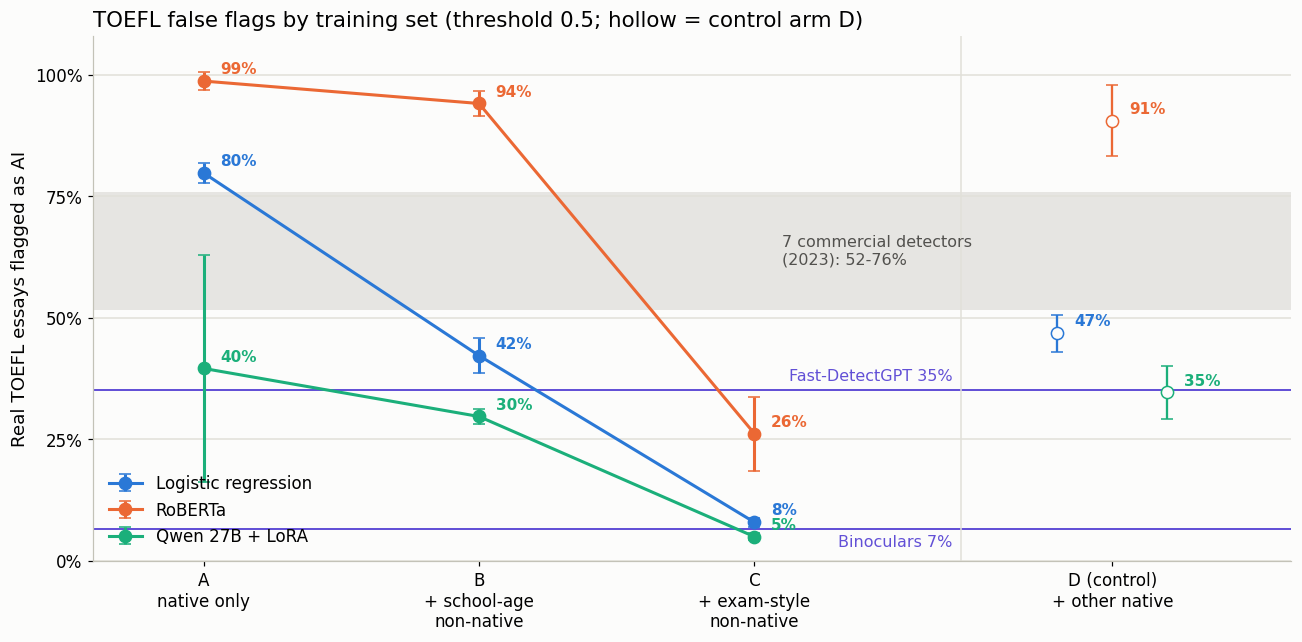

           A    B    C    D
LR       80%  42%   8%  47%
RoBERTa  99%  94%  26%  91%
Qwen27B  40%  30%   5%  35%


In [10]:
com_rates = [M.flag_rate(com[(com.detector == d) & (com.corpus == M.TOEFL)].score) for d in M.COMMERCIAL]
fig = P.trend(CM, com_rates, CM.loc[("Binoculars", "-"), "FP_TOEFL"], CM.loc[("FastDetectGPT", "-"), "FP_TOEFL"])
fig.savefig(FIG_DIR / "fig2_trend_ABC_D.png", bbox_inches="tight"); plt.show()
print(pd.DataFrame({m: [f"{CM.loc[(m, a), 'FP_TOEFL'] * 100:.0f}%" for a in "ABCD"] for m in ["LR", "RoBERTa", "Qwen27B"]}, index=list("ABCD")).T)

## 8. Figure 3: precision / recall / F1 table
Means over seeds. The commercial row shows the range over the seven detectors.

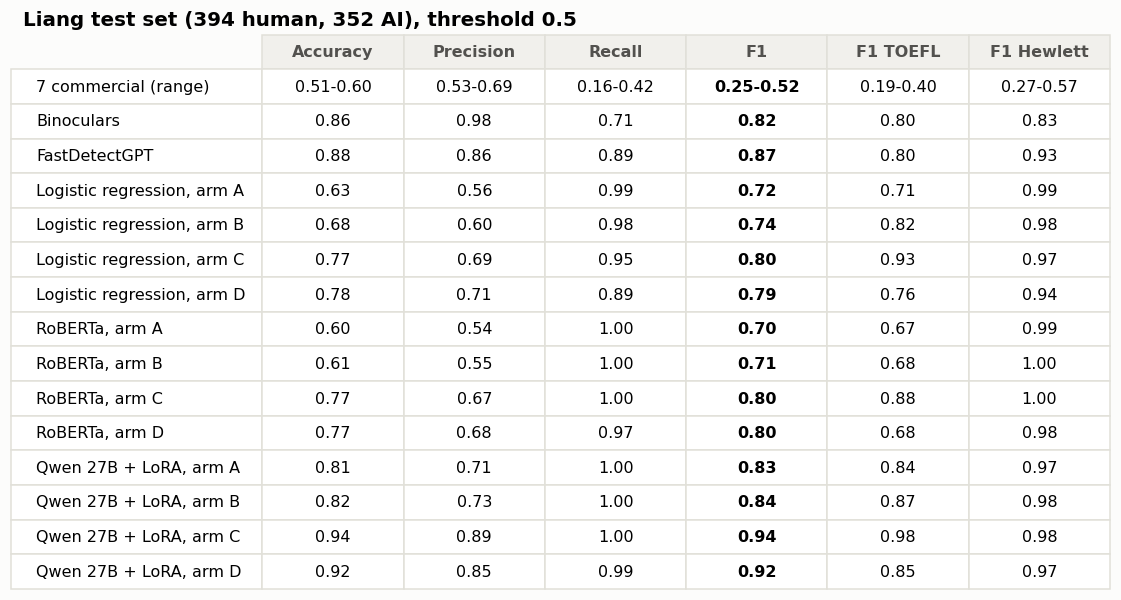

In [11]:
names = {"LR": "Logistic regression", "RoBERTa": "RoBERTa", "Qwen27B": "Qwen 27B + LoRA"}
cm_rows = PRF[PRF.model == "commercial"]
tab = {"7 commercial (range)": {k: f"{cm_rows[k].min():.2f}-{cm_rows[k].max():.2f}" for k in keys}}
for name in ["Binoculars", "FastDetectGPT"]:
    tab[name] = {k: f"{PRF[PRF.model == name][k].iloc[0]:.2f}" for k in keys}
for m in ["LR", "RoBERTa", "Qwen27B"]:
    for a in "ABCD":
        g = PRF[(PRF.model == m) & (PRF.arm == a)]
        tab[f"{names[m]}, arm {a}"] = {k: f"{g[k].mean():.2f}" for k in keys}
tab = pd.DataFrame(tab).T.rename(columns={"accuracy": "Accuracy", "precision": "Precision", "recall": "Recall", "f1": "F1",
                                         "f1_bal_TOEFL": "F1 TOEFL", "f1_bal_Hewlett": "F1 Hewlett"})
fig = P.table_figure(tab, "Liang test set (394 human, 352 AI), threshold 0.5", highlight_col="F1")
fig.savefig(FIG_DIR / "fig3_precision_recall_f1.png", bbox_inches="tight"); plt.show()

## 9. Figure 4: commercial detectors, TOEFL vs native essays
Archived scores from Liang et al. (2023), threshold 0.5.

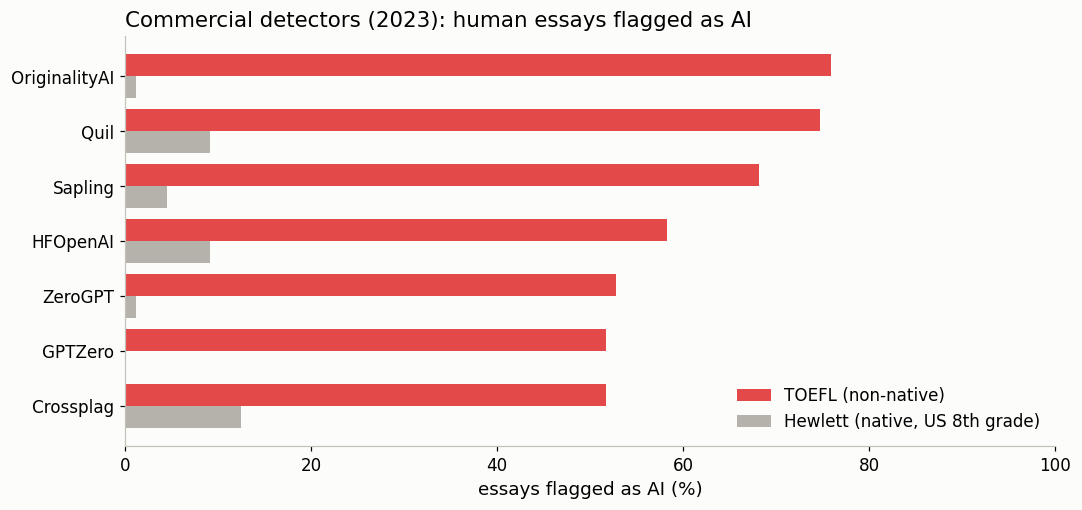

In [12]:
e = ext[ext.kind.str.startswith("commercial")].sort_values("TOEFL_flagged")
fig, ax = plt.subplots(figsize=(10, 4.8)); y = np.arange(len(e))
ax.barh(y + 0.2, e.TOEFL_flagged * 100, height=0.4, color=P.C_TOEFL, label="TOEFL (non-native)")
ax.barh(y - 0.2, e.Hewlett_flagged * 100, height=0.4, color=P.GRAY, label="Hewlett (native, US 8th grade)")
ax.set_yticks(y); ax.set_yticklabels(e.detector); ax.set_xlim(0, 100); ax.set_xlabel("essays flagged as AI (%)")
ax.legend(frameon=False, loc="lower right"); ax.set_title("Commercial detectors (2023): human essays flagged as AI", loc="left")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig4_commercial.png", bbox_inches="tight"); plt.show()

## 10. Summary of checks

In [13]:
summary = pd.DataFrame([
    dict(table="Table 1 (flag rates, AUCs) vs model_comparison_all.csv", result="PASS" if (chk1.result == "PASS").all() else "FAIL"),
    dict(table="Table 2 (primary endpoints, per run) vs followup_runs*.csv", result="PASS" if (chk2.result == "PASS").all() else "FAIL"),
    dict(table="Table 2b (commercial + open-source) vs metrics_runs.csv", result="PASS" if (chk3.result == "PASS").all() else "FAIL"),
    dict(table="Table 3 (precision/recall/F1, per run) vs prf1_runs.csv", result="PASS" if (chk4.result == "PASS").all() else "FAIL"),
    dict(table="Paired tests vs followup_paired*.csv", result="PASS" if (chk5.result == "PASS").all() else "FAIL")])
display(summary)
print(f"CHECK SUMMARY: {(summary.result == 'PASS').sum()} PASS, {(summary.result == 'FAIL').sum()} FAIL. "
      "All numbers replayed from saved scores; no detector was run in this notebook.")
print("Figures saved to", FIG_DIR)
print(f"Notebook finished in {time.time() - T0:.0f} s (mode {MODE}).")

,table,result
0,"Table 1 (flag rates, AUCs) vs model_comparison...",PASS
1,"Table 2 (primary endpoints, per run) vs follow...",PASS
2,Table 2b (commercial + open-source) vs metrics...,PASS
3,"Table 3 (precision/recall/F1, per run) vs prf1...",PASS
4,Paired tests vs followup_paired*.csv,PASS


CHECK SUMMARY: 5 PASS, 0 FAIL. All numbers replayed from saved scores; no detector was run in this notebook.
Figures saved to outputs/figures
Notebook finished in 4 s (mode FAST).
